# Drivers de comportamiento del cliente: NovaRetail+

Análisis correlacional (Pearson, Spearman, punto-biserial y V de Cramér) de los factores asociados al ingreso por cliente.

**Autora:** Gabriela López Larios · Analista de Datos  
Proyecto del Bootcamp de Análisis de Datos de TripleTen (2026) con datos simulados. Consulta el `README.md` del repositorio para ver el resumen de hallazgos.

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+

NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.

In [3]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` está cargada como float64 podríamos convertirla a entero.

**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.
La columna `id_cliente` actúa únicamente como identificador único y no requiere análisis estadístico.

In [4]:
# Corregir el tipo de dato
# Convertir la columna edad a tipo entero
df['edad'] = df['edad'].astype(int)

In [5]:
# verificar cambios
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


#### Explorar variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
df[['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']].describe().T

,count,mean,std,min,25%,50%,75%,max
edad,15000.0,38.262400,11.492378,18.0,30.0000,38.000,46.0000,75.00
nivel_ingreso,15000.0,30019.704782,9833.166305,8000.0,23127.0975,30023.745,36768.4400,74790.84
visitas_mes,15000.0,10.029000,3.158189,1.0,8.0000,10.000,12.0000,25.00
compras_mes,15000.0,1.206467,1.105284,0.0,0.0000,1.000,2.0000,8.00
gasto_publicidad_dirigida,15000.0,20.149301,10.880724,0.0,12.3100,19.730,27.2925,75.51
satisfaccion,15000.0,3.603693,0.685300,1.0,3.1000,3.600,4.1000,5.00
ingreso_anual,15000.0,36.594180,34.484888,0.0,0.0000,30.705,58.2200,244.69


Diagnóstico inicial de variables numéricas
 
- `edad` : Muestra una simetria perfecta; la media y la mediana coinciden en 38 años, refleja una base de clientes distribuida entre los 18 y 75 años.
- `nivel_ingreso` : Presenta una distribucion estable y centrda con un promedio de $30,019.70, donde la mitad de la base se concentra en un rango intermedio.
- `visitas_mes` : Los usuarios interactúan de forma constante con una media de 10 visitas mensuales y una desviacion estándar baja (3.15), lo que indica un patrón de navegacion homogeneo.
- `compras_mes` : Desctaca que al menos el 25% de los clientes registra 0 compras en el mes, evidenciando una brecha importante entre visitar la plataforma y concretar una transacción.
- `gasto_publicidad_dirigida` : Comienza desde 0, lo que indica que existe un segmento al que no se le destina inversión publicitaria directa.
- `satisfacción` : Se tiene un nivel favorable al contar con un promedio de 3.6 sobre 5, con una dispersión redicida que muestra opiniones mayormente estables y positivas.
- `ingreso_anual` : Presenta un sesgo hacia la derecha y valores en cero; el 25% de la muestra tiene 0.0, la media (36.59) supera a la mediana (30.70) y el máximo asciende a 244.69, el cual podria tratarse de un cliente de alto valor.

#### Explorar variables binarias

In [7]:
# Verificar que cada columna tenga únicamente dos valores posibles

for col in ['miembro_premium', 'abandono']:
    print(f"\n---{col}---")
    print("Valores unico:", df[col].unique())
    print(df[col].value_counts(dropna=False))
    print(df[col].value_counts(normalize=True).mul(100).round(2).astype(str) + "%")


---miembro_premium---
Valores unico: [0 1]
0    12911
1     2089
Name: miembro_premium, dtype: int64
0    86.07%
1    13.93%
Name: miembro_premium, dtype: object

---abandono---
Valores unico: [0 1]
0    12739
1     2261
Name: abandono, dtype: int64
0    84.93%
1    15.07%
Name: abandono, dtype: object


Diagnóstico inicial de variables binarias

- `miembro_premium` — Solo el 13.9% de la base cuenta con membresia de pago.
- `abandono` — La tasa de cancelacion de clientes es del 15.07%.

Ambas variables muestran un desequilibrio claro (~85% vs ~15%). Esto es crucial porque advierte que al calcular correlaciones, la clase minoritaria tiene un peso reducido en la muestra total.

#### Explorar variables categóricas

In [8]:
# Verificar el número de valores únicos por variable categórica

for col in ['tipo_dispositivo','region']:
    print(f"\n---{col}---")
    print("Valores unicos:", df[col].nunique())
    print("Categorias:", df[col].unique())
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True).mul(100).round(2).astype(str) + "%")



---tipo_dispositivo---
Valores unicos: 3
Categorias: ['móvil' 'tablet' 'escritorio']
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64
móvil         65.45%
escritorio     24.8%
tablet         9.75%
Name: tipo_dispositivo, dtype: object

---region---
Valores unicos: 4
Categorias: ['norte' 'sur' 'este' 'oeste']
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64
norte     29.3%
oeste     25.4%
sur      24.84%
este     20.46%
Name: region, dtype: object


In [9]:
# Explorar variables categóricas y cómo se distribuyen

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — El dispositivo movil representa la gran mayoria de las interacciones con 9818 registros (65.45%).
- `region` - Las 4 regiones estan bien distribuidas. La region norte es lider con 4,395 (29.3%) registros, mientras que la region este tiene menor presencia con 3,069 (20.46%) registros.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

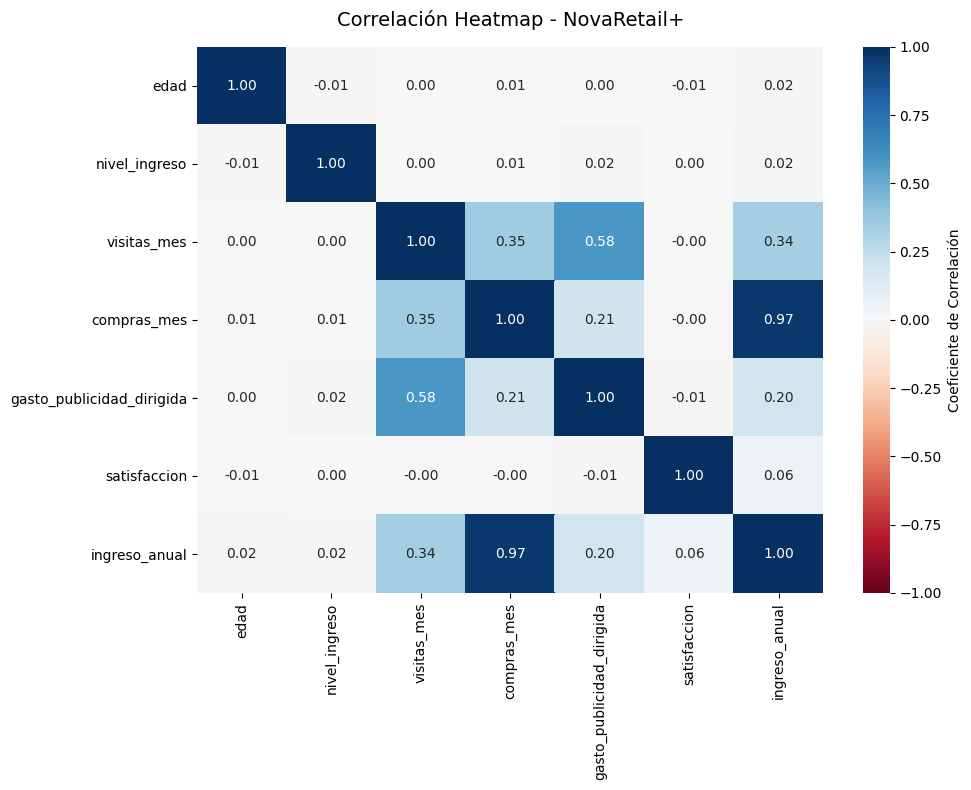

In [10]:
# Visualizar la matriz de correlación para identificar relaciones

# Seleccion de variables numéricas
num_cols = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']

# Matriz de correlacion
matriz_corr= df[num_cols].corr()

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='RdBu', center=0, vmin=-1,  vmax=1, cbar_kws={'label':'Coeficiente de Correlación'})

plt.title('Correlación Heatmap - NovaRetail+', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

Observaciones generales (Heatmap)  
- La matriz muestra que la mayoría de las variables numéricas del dataset no presentan una relación lineal entre sí, registrando valores cercanos a cero. Sin embargo, se observa un bloque claramente definido de interacción digital y transaccional donde se concentran las asociaciones más relevantes:
  - Existe una relación positiva moderada-fuerte entre visitas_mes y gasto_publicidad_dirigida (0.58), así como una asociación moderada entre visitas_mes y compras_mes (0.35).
  - Las variables edad, nivel_ingreso y satisfaccion muestran coeficientes prácticamente nulos (r ≤ 0.02) frente al resto del conjunto de datos. Esto indica una ausencia total de colinealidad o relación lineal con las métricas de comportamiento dentro de la plataforma.

Observaciones respecto a `ingreso_anual`  
- Al analizar directamente la fila/columna de la variable objetivo **(ingreso_anual)**, se destacan tres niveles de asociación lineal:
  - Relación Fuerte : `compras_mes` (r = 0.97): Presenta una relación lineal positiva casi perfecta. El volumen transaccional mensual (compras_mes) es la variable que más alineada está con la generación de ingresos anuales (ingreso_anual) para la empresa.
  - Relaciones Moderadas / Débiles: `visitas_mes` (r = 0.34): Existe una relación positiva moderada. Un mayor tráfico de visitas acompaña a un mayor ingreso, aunque con menor intensidad que las compras efectivas. `gasto_publicidad_dirigida` (r = 0.20): Muestra una relación positiva débil. Los usuarios con mayor presupuesto en anuncios personalizados (gasto_publicidad_dirigida) tienden a registrar un ingreso ligeramente mayor.Sin embargo,un mayor gasto en pauta no garantiza por sí solo un aumento significativo en la facturación del cliente. `satisfaccion` (r = 0.06): La percepción de satisfacción muestra una asociación lineal débil e imperceptible con el gasto total generado por el usuario.
  - Sin Asociación Lineal: `edad` (r = 0.02) y `nivel_ingreso` (r = 0.02): Las variables demográficas no muestran ningún grado de correlación lineal con la facturación que genera el cliente, lo que indica que el retorno económico depende enteramente de la dinámica transaccional dentro de la aplicación y no del perfil sociodemográfico del usuario.

### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.
 
No es necesario generar un scatterplot general por que solo generaria ruido visual. Como observamos en el heatmap, variables como edad, nivel_ingreso, satisfaccion tienen correlaciones de 0.00 a 0.02 con casi todas las demás. Un scatterplot de estas variables mostrará únicamente "nubes de puntos" amorfas sin patrón, lo que no aporta valor al reporte y distrae de los hallazgos importantes.

### Scatterplot para pares clave

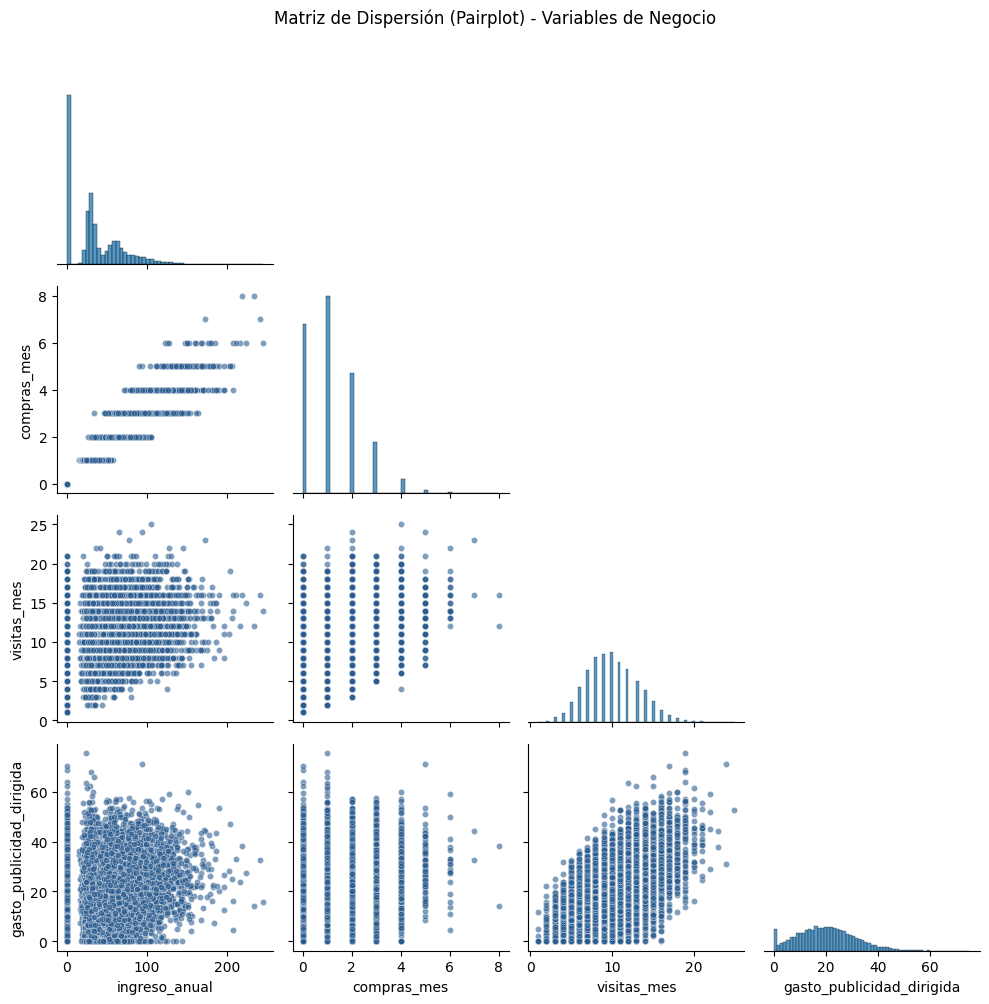

In [11]:
# Visualizar pares de variables con relaciones moderadas o fuertes

# Definimos la lista de columnas numéricas de interés

columnas_interes = ["ingreso_anual", "compras_mes", "visitas_mes", "gasto_publicidad_dirigida"]

sns.pairplot(
    df[columnas_interes],
    corner=True,                      
    diag_kind="hist",                 
    kind="scatter",                   
    plot_kws={'alpha': 0.6, 's': 20, 'color': '#2b5c8f'}
    )

plt.suptitle("Matriz de Dispersión (Pairplot) - Variables de Negocio", y=1.0)
plt.tight_layout()
plt.show()


1. **`compras_mes vs. ingreso_anual`** Presenta una `dirección positiva`. A mayor número de compras, mayor ingreso anual. Su `dispersión es baja`. Los puntos se agrupan en franjas horizontales discretas muy bien alineadas linealmente con los valores de ingreso. La `presencia de outliers va de baja a moderada`. Se observan pocos casos atípicos en los extremos superiores (clientes con 7 u 8 compras e ingresos superiores a 200). Presenta una `colinealidad alta`. Muestran una asociación lineal sumamente estrecha (r = 0.97), por lo que incluir ambas como variables predictoras independientes en un mismo modelo lineal generaría problemas severos de multicolinealidad.

2. **`visitas_mes vs. ingreso_anual`** Presenta una `dirección positiva`. Su `dispersión va de media a alta`. La nube de puntos se expande verticalmente a lo largo del eje de ingresos. La `presencia de outliers es moderada`. Hay valores atípicos en visitas (> 20) e ingresos superiores a 200. Presenta un `colinealidad de baja a moderada`. Existe asociación lineal (r = 0.34), pero la dispersión es suficiente para que aporten información distinta en un modelo.

3. **`gasto_publicidad_dirigida vs. ingreso_anual`** Presenta una `dirección positiva`. Su `dispersión es alta`. Los puntos forman una nube difusa con un rango amplio de gasto publicitario para un mismo nivel de ingresos. La `presencia de outliers es alta`. Destacan varios valores atípicos con gastos publicitarios elevados (> 60) repartidos en distintos niveles de ingreso. Presenta una `colinealidad baja`. La correlación es débil (r = 0.20), por lo que no representa riesgo de colinealidad respecto al ingreso.

4. **`visitas_mes vs. compras_mes`** Presenta una `dirección positiva`. Un mayor número de visitas se acompaña de un mayor número de compras. Su `dispersión es media`. Muestra columnas verticales por cada nivel discreto de compras. La `presencia de outliers es baja`. La mayoría del volumen se concentra en visitas entre 5 y 15 para compras de 1 a 4. Presenta una `colinealidad moderada`. La relación (r = 0.35) refleja que el tráfico acompaña a la transacción, pero no lo suficiente para causar un problema estricto de multicolinealidad.

5. **`gasto_publicidad_dirigida vs. compras_mes`** Presenta una `dirección positiva (muy leve)`. Su `dispersión es alta`. Para cualquier nivel de compras (p. ej., 1 o 2 compras), existe una variabilidad enorme en el gasto de publicidad asignado (0 a 60). La `presencia de outliers es alta`. Se identifican observaciones aisladas con gasto en pauta superior a 60 en niveles bajos de compra. Presenta una `colinealidad nula o muy baja`. No hay riesgo de colinealidad entre estas dos variables (r = 0.21).

6. **`gasto_publicidad_dirigida vs. visitas_mes`** Presenta una `dirección positiva`. Su `dispersión es media`. Muestra una clara tendencia ascendente donde a mayor gasto en publicidad dirigida, mayor es el número de visitas recibidas. La `presencia de outliers es moderada`. Algunos puntos en el extremo superior de visitas (> 20) y gasto (> 60). Presenta una `colinealidad de moderada a alta`. Es la segunda relación más fuerte del gráfico (r = 0.58).

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [12]:
# Calcular correlación entre variables relevantes

def corr_numerica(df, num_cols, metodo="pearson"):
    matriz = df[num_cols].corr(method=metodo)
    return (matriz.style
            .background_gradient(cmap="coolwarm", vmin=-1, vmax=1, axis=None)
            .format("{:.2f}"))

corr_matriz= corr_numerica(df, num_cols, metodo="pearson")
corr_matriz

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
edad,1.00,-0.01,0.00,0.01,0.00,-0.01,0.02
nivel_ingreso,-0.01,1.00,0.00,0.01,0.02,0.00,0.02
visitas_mes,0.00,0.00,1.00,0.35,0.58,-0.00,0.34
compras_mes,0.01,0.01,0.35,1.00,0.21,-0.00,0.97
gasto_publicidad_dirigida,0.00,0.02,0.58,0.21,1.00,-0.01,0.20
satisfaccion,-0.01,0.00,-0.00,-0.00,-0.01,1.00,0.06
ingreso_anual,0.02,0.02,0.34,0.97,0.20,0.06,1.00


In [13]:
# Calcular correlación entre variables relevantes

def corr_numerica(df, num_cols, metodo="spearman"):
    matriz = df[num_cols].corr(method=metodo)
    return (matriz.style
            .background_gradient(cmap="coolwarm", vmin=-1, vmax=1, axis=None)
            .format("{:.2f}"))

corr_matriz= corr_numerica(df, num_cols, metodo="spearman")
corr_matriz

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
edad,1.00,-0.01,0.01,0.02,0.00,-0.01,0.02
nivel_ingreso,-0.01,1.00,0.00,0.01,0.02,0.01,0.03
visitas_mes,0.01,0.00,1.00,0.33,0.56,-0.00,0.32
compras_mes,0.02,0.01,0.33,1.00,0.19,-0.00,0.97
gasto_publicidad_dirigida,0.00,0.02,0.56,0.19,1.00,-0.01,0.18
satisfaccion,-0.01,0.01,-0.00,-0.00,-0.01,1.00,0.06
ingreso_anual,0.02,0.03,0.32,0.97,0.18,0.06,1.00


Observaciones de correlación

El contraste entre los coeficientes de **Pearson** (relaciones lineales) y **Spearman** (relaciones monotónicas) permite validar la consistencia de las asociaciones y detectar posibles riesgos estructurales para futuros modelos.

**Dirección y Magnitud de las Relaciones**
* **`compras_mes` vs. `ingreso_anual` ($r = 0.97$ | $\rho = 0.97$):**
  * **Dirección:** Positiva (+).
  * **Magnitud:** **Extremadamente fuerte / Casi perfecta**.
  * Ambas métricas coinciden de forma exacta. A mayor volumen de compras mensuales, el ingreso anual generado se incrementa de forma directa y proporcional.

* **`visitas_mes` vs. `gasto_publicidad_dirigida` ($r = 0.58$ | $\rho = 0.56$):**
  * **Dirección:** Positiva (+).
  * **Magnitud:** **Moderada a fuerte**.
  * Muestra una co-ocurrencia consistente entre el esfuerzo en publicidad dirigida y un mayor flujo de visitas mensuales a la plataforma.

* **`visitas_mes` vs. `ingreso_anual` ($r = 0.34$ | $\rho = 0.32$):**
  * **Dirección:** Positiva (+).
  * **Magnitud:** **Moderada**. Un mayor tráfico de visitas co-ocurre con un mayor ingreso, aunque con menor intensidad que el volumen de compras directas.

* **`gasto_publicidad_dirigida` vs. `ingreso_anual` ($r = 0.20$ | $\rho = 0.18$):**
  * **Dirección:** Positiva (+).
  * **Magnitud:** **Débil**. La relación directa con el ingreso final es baja, sugiriendo que la publicidad tiene una mayor asociación con las *visitas* que con la *conversión monetaria directa*.

* **`edad`, `nivel_ingreso` y `satisfaccion` ($r, \rho \in [-0.01, 0.06]$):**
  * **Magnitud:** **Nula / Despreciable**. Ninguna de estas variables presenta una asociación lineal o monotónica relevante con el ingreso anual ni con el resto de las variables numéricas.

---

La diferencia entre los coeficientes de Pearson y Spearman en todos los pares es marginal ($\Delta \le 0.02$).
Las relaciones observadas son **estrictamente lineales y homogéneas**. No existe evidencia de distorsiones graves causadas por valores atípicos (*outliers*) extremos ni de relaciones no lineales complejas (como formas en "U").

---

**Alerta de Multicolinealidad (Consideración para Modelos Predictivos)**
Si se planea utilizar este conjunto de variables para construir modelos de regresión u optimización, se deben considerar dos focos de redundancia de información:

1. **Colinealidad Crítica (`compras_mes` vs. `ingreso_anual`):**
   * Con un coeficiente de $0.97$, la variable `compras_mes` explica por sí sola cerca del $94\%$ de la variabilidad del `ingreso_anual` ($R^2 \approx 0.94$). 
   * **Riesgo:** Incluirla como variable predictora (*feature*) causará *data leakage* o redundancia casi absoluta, opacando el efecto de otras variables de negocio.
2. **Colinealidad Moderada (`gasto_publicidad_dirigida` vs. `visitas_mes`):**
   * La correlación de $0.58$ entre ambas variables independientes sugiere cierta solapación de información.
   * **Recomendación:** Se sugiere evaluar el Factor de Inflación de la Varianza (VIF) antes de incluirlas simultáneamente en un modelo lineal.

### Punto-biserial

=== RESULTADOS DE CORRELACIÓN PUNTO-BISERIAL ===


,Variable Binaria,r_pb (Pearson),p-valor,Es Significativo (p < 0.05),Media (Grupo 0),Media (Grupo 1)
0,miembro_premium,0.0931,3.094308e-30,True,35.30,44.58
1,abandono,-0.0028,7.294692e-01,False,36.64,36.36


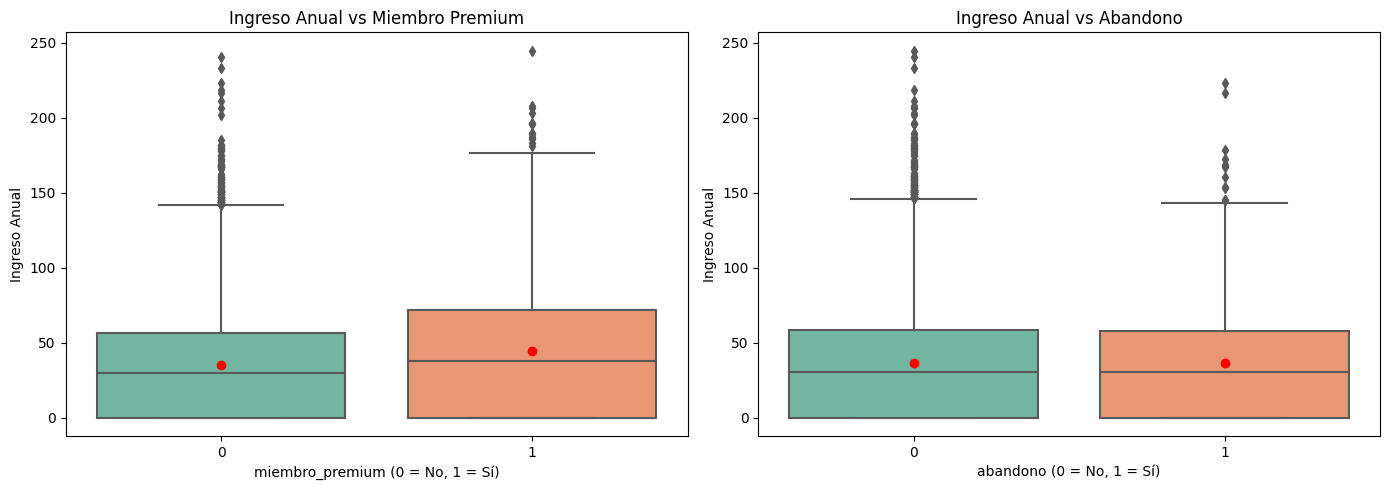

In [14]:
# Calcular correlación entre variables relevantes

from scipy import stats

# 1. Definición de variables específicas
binary_cols = ['miembro_premium', 'abandono']
target_continuous = 'ingreso_anual'

# 2. Cálculo de la Correlación Punto-Biserial y Pruebas de Significancia
results = []

for b_col in binary_cols:
    # Eliminación de nulos si existieran para evitar errores en scipy
    clean_data = df[[b_col, target_continuous]].dropna()
    
    # Cálculo de Coeficiente Punto-Biserial y valor p
    r_pb, p_value = stats.pointbiserialr(clean_data[b_col], clean_data[target_continuous])
    
    # Métricas descriptivas por grupo (Media y Desviación Estándar)
    mean_0 = clean_data[clean_data[b_col] == 0][target_continuous].mean()
    mean_1 = clean_data[clean_data[b_col] == 1][target_continuous].mean()
    
    results.append({
        'Variable Binaria': b_col,
        'r_pb (Pearson)': round(r_pb, 4),
        'p-valor': p_value,
        'Es Significativo (p < 0.05)': p_value < 0.05,
        'Media (Grupo 0)': round(mean_0, 2),
        'Media (Grupo 1)': round(mean_1, 2)
    })

# Convertir a DataFrame para visualización clara de resultados
df_results = pd.DataFrame(results)
print("=== RESULTADOS DE CORRELACIÓN PUNTO-BISERIAL ===")
display(df_results)

# 3. Visualización comparativa (Boxplots y Stripplots)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, b_col in enumerate(binary_cols):
    sns.boxplot(
        data=df, 
        x=b_col, 
        y=target_continuous, 
        ax=axes[idx], 
        palette='Set2',
        showmeans=True,
        meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red"}
    )
    axes[idx].set_title(f'{target_continuous.replace("_", " ").title()} vs {b_col.replace("_", " ").title()}')
    axes[idx].set_xlabel(f'{b_col} (0 = No, 1 = Sí)')
    axes[idx].set_ylabel('Ingreso Anual')

plt.tight_layout()
plt.show()



Observaciones Punto-biserial

#### A. Ingreso Anual vs. Membresía Premium
* **Dirección:** Positiva (+).
* **Magnitud:** Baja ($r_{pb} = 0.0931$).
* **Significancia:** Alta ($p < 0.001$).
* **Conclusión:** Existe una ligera tendencia a que los miembros Premium cuenten con ingresos anuales superiores (media de 44.58 vs 35.30). No obstante, la magnitud baja indica que el ingreso no es el factor determinante para la suscripción Premium.

#### B. Ingreso Anual vs. Abandono (Churn)
* **Dirección:** Negativa (-) / Indiferente.
* **Magnitud:** Nula ($r_{pb} = -0.0028$).
* **Significancia:** No significativa ($p = 0.729$).
* **Conclusión:** Existe independencia entre el ingreso del cliente y el riesgo de abandono. Las estrategias orientadas a retener clientes no deben priorizar el nivel de ingreso como variable de riesgo.

### V de Cramér

In [15]:
# Función para calcular V de Cramér

cat_cols = ['tipo_dispositivo', 'region']

from scipy.stats import chi2_contingency

def cramer_v_analysis(df, col1, col2):
    """
    Calcula la prueba Chi-cuadrada y el coeficiente V de Cramér 
    entre dos variables categóricas.
    """
    # 1. Tabla de contingencia (frecuencias observadas)
    tabla = pd.crosstab(df[col1], df[col2])
    
    # 2. Prueba Chi-cuadrada de independencia
    chi2, p_val, dof, expected = chi2_contingency(tabla)
    
    # 3. Cálculo de V de Cramér
    n = tabla.values.sum()
    k = min(tabla.shape) - 1
    v = np.sqrt(chi2 / (n * k)) if k > 0 else 0.0
    
    # Formatear resultados en un DataFrame para presentación limpia
    resultado = pd.DataFrame({
        'Variable 1': [col1],
        'Variable 2': [col2],
        'Estadístico Chi2': [round(chi2, 4)],
        'Grados de Libertad (dof)': [dof],
        'p-valor': [p_val],
        'Es Significativo (p < 0.05)': [p_val < 0.05],
        'V de Cramér': [round(v, 4)]
    })
    
    return resultado, tabla

In [16]:
# Aplicar V de Cramér en variables relevantes

df_cramer, tabla_contingencia = cramer_v_analysis(df, 'region', 'tipo_dispositivo')

print("=== TABLA DE CONTINGENCIA (FRECUENCIAS) ===")
display(tabla_contingencia)

print("\n=== RESULTADO DE ASOCIACIÓN (V DE CRAMÉR) ===")
display(df_cramer)

=== TABLA DE CONTINGENCIA (FRECUENCIAS) ===


tipo_dispositivo,escritorio,móvil,tablet
region,,,
este,766,2003,300
norte,1125,2843,427
oeste,935,2489,386
sur,894,2483,349



=== RESULTADO DE ASOCIACIÓN (V DE CRAMÉR) ===


,Variable 1,Variable 2,Estadístico Chi2,Grados de Libertad (dof),p-valor,Es Significativo (p < 0.05),V de Cramér
0,region,tipo_dispositivo,4.5967,6,0.596477,False,0.0124


Observaciones V de Cramér

### Diagnóstico: Categorías `region` vs `tipo_dispositivo`

* **Prueba Aplicada:** Chi-cuadrada de independencia ($\chi^2$) y Coeficiente $V$ de Cramér.
* **Estadísticos:** $\chi^2 = 4.5967$, $\text{dof} = 6$, $p\text{-valor} = 0.5965$, $V = 0.0124$.

#### Conclusiones de Negocio:
1. **Independencia Estadística:** Dado que el $p\text{-valor} (0.5965) > 0.05$, confirmamos que no hay relación estadísticamente significativa entre la región y el dispositivo utilizado.
2. **Homogeneidad de Comportamiento:** La distribución de uso (móvil $\approx 65\%$, escritorio $\approx 25\%$, tablet $\approx 10\%$) se replica de forma casi idéntica en todas las regiones (este, norte, oeste, sur).
3. **Implicación Práctica:** No es necesario diseñar estrategias de optimización de interfaz o campañas publicitarias por dispositivo diferenciadas por zona geográfica.

Basarse solo en el $p$-valor te expone al riesgo de tomar decisiones de negocio costosas basadas en relaciones que son estadísticamente "reales" pero irrelevantes en la práctica. Basarse solo en la V de Cramér te expone a actuar sobre patrones que podrían ser simple ruido de la muestra. Reportar ambos garantiza rigor técnico y valor práctico.

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 — Ligera asociación positiva entre el ingreso anual y la suscripción a membresías premium

**Evidencia visual:** Boxplot de `ingreso_anual` vs `miembro_premium` (los clientes premium presentan un promedio ligeramente desplazado hacia arriba).  
**Evidencia numérica:** Correlación Punto-biserial ($r_{pb} = 0.0931$, $p = 3.09 \times 10^{-30}$).  

**Interpretación**  
Existe una relación positiva y estadísticamente significativa entre el ingreso anual y el estatus premium. Los miembros premium tienen un ingreso medio ligeramente superior (44.58 vs. 35.30 unidades); sin embargo, la magnitud de la asociación es débil ($r_{pb} < 0.10$).  

**No podemos afirmar**  
No podemos afirmar que tener un mayor ingreso anual sea la causa por la cual un cliente decide adquirir la membresía premium, ni que el ingreso por sí solo garantice la conversión de un usuario.  

**Implicación de negocio**  
Es posible que los usuarios con mayor capacidad adquisitiva muestren una disposición ligeramente superior a pagar por ventajas exclusivas. Como hipótesis de negocio, se sugiere que variables como el valor percibido del servicio o la frecuencia de uso influyen más en la conversión que el poder adquisitivo del cliente.

---

### Hallazgo 2 — Independencia absoluta entre el nivel de ingreso anual y el abandono de clientes (Churn)

**Evidencia visual:** Boxplot de `ingreso_anual` vs `abandono` (distribuciones de ingreso prácticamente idénticas entre ambos grupos).  
**Evidencia numérica:** Correlación Punto-biserial ($r_{pb} = -0.0028$, $p = 0.7290$).  

**Interpretación**  
El ingreso anual del cliente no presenta relación lineal ni diferencia estadísticamente significativa con la probabilidad de abandono. Las medias de ingreso entre quienes permanecen (36.64) y quienes se dan de baja (36.36) son prácticamente iguales.  

**No podemos afirmar**  
No podemos afirmar que los clientes de bajos ingresos sean más propensos a cancelar el servicio por razones financieras, ni que los de altos ingresos estén "asegurados" contra la deserción.  

**Implicación de negocio**  
El precio o nivel socioeconómico no parece ser el detonante del abandono. Como hipótesis, la deserción podría responder a factores de experiencia de usuario, mala calidad en la atención o falta de engagement, por lo que las estrategias de retención no deben segmentarse por nivel de ingresos.

### Hallazgo 3 — Distribución uniforme y no asociada del tipo de dispositivo según la región geográfica

**Evidencia visual:** Tabla de contingencia y frecuencias de uso por región (móvil $\approx 65\%$, escritorio $\approx 25\%$, tablet $\approx 10\%$).  
**Evidencia numérica:** Coeficiente $V$ de Cramér ($V = 0.0124$, $\chi^2 = 4.5967$, $p = 0.5965$).  

**Interpretación**  
No existe asociación entre la región geográfica del cliente y el tipo de dispositivo que utiliza. La V de Cramér cercana a cero y el valor $p > 0.05$ confirman la independencia total entre ambas variables categóricas.  

**No podemos afirmar**  
No podemos afirmar que ciertas regiones geográficas tengan barreras tecnológicas o preferencias exclusivas por un ecosistema de dispositivos específico.  

**Implicación de negocio**  
El comportamiento tecnológico del usuario es homogéneo a nivel nacional. Como hipótesis, los patrones de adopción de dispositivos obedecen al contexto situacional de navegación y no a características regionales, por lo que no se requiere adaptar interfaces por zona geográfica.

## Sección 6 - Limitaciones y próximos pasos

### Limitaciones

* **Ausencia de causalidad:** Los coeficientes evaluados (Pearson, Punto-biserial y V de Cramér) miden únicamente la fuerza de asociación entre variables; no permiten determinar relaciones de causa y efecto.
* **Variables omitidas (confusoras):** El análisis actual no incluye métricas clave como el precio de los planes, promociones aplicadas, antigüedad del cliente o interacciones con soporte técnico, las cuales podrían explicar mejor el abandono o la conversión.
* **Sensibilidad a valores extremos (Outliers):** Coeficientes lineales como Pearson y Punto-biserial son sensibles a valores extremos en variables financieras como `ingreso_anual`, lo que puede atenuar o sesgar las asociaciones detectadas.
* **Límite en patrones no lineales:** Las métricas empleadas detectan relaciones lineales o monótonas; dependencias complejas o no lineales podrían estar ocultas tras coeficientes cercanos a cero.

---

### Próximos pasos

* **Segmentación avanzada (Clustering):** Aplicar algoritmos no supervisados (como K-Means o DBSCAN) agrupando por `visitas_mes`, `compras_mes` y `satisfaccion` para identificar perfiles de comportamiento antes de evaluar correlaciones por subgrupo.
* **Modelado predictivo (Regresión Logística):** Construir un modelo multivariado para predecir la probabilidad de `abandono`, controlando simultáneamente el efecto de múltiples variables y aislando el impacto de cada una.
* **Ingeniería de características:** Incluir nuevas métricas relativas (ej. `compras_mes` / `visitas_mes` como tasa de conversión individual) para evaluar relaciones de interacción más profundas.
* **Diseño de experimentos A/B:** Diseñar experimentos controlados (ej. pruebas de precio o incentivos de retención) para evaluar de forma rigurosa relaciones causales sobre la conversión a `miembro_premium` y la disminución de `abandono`.